Device: cpu
Using CPU. Training may take longer.

Loading CIFAR-10 dataset...


100%|██████████| 170M/170M [40:03<00:00, 70.9kB/s]


Training samples: 800
Validation samples: 200

MODEL: VGG

Loading pretrained VGG...
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 74.7MB/s]


VGG | Epoch 1/2 | Loss: 1.2594 | Train Accuracy: 56.75% | Validation Accuracy: 61.00%
VGG | Epoch 2/2 | Loss: 0.6098 | Train Accuracy: 78.38% | Validation Accuracy: 64.50%
VGG time: 4.00 minutes

MODEL: RESNET

Loading pretrained RESNET...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 88.1MB/s]


RESNET | Epoch 1/2 | Loss: 2.0069 | Train Accuracy: 30.50% | Validation Accuracy: 38.50%
RESNET | Epoch 2/2 | Loss: 1.2890 | Train Accuracy: 58.88% | Validation Accuracy: 54.50%
RESNET time: 0.60 minutes

MODEL: GOOGLENET

Loading pretrained GOOGLENET...
Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 72.4MB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


GOOGLENET | Epoch 1/2 | Loss: 3.4955 | Train Accuracy: 26.88% | Validation Accuracy: 43.50%
GOOGLENET | Epoch 2/2 | Loss: 2.7754 | Train Accuracy: 54.50% | Validation Accuracy: 51.00%
GOOGLENET time: 0.96 minutes


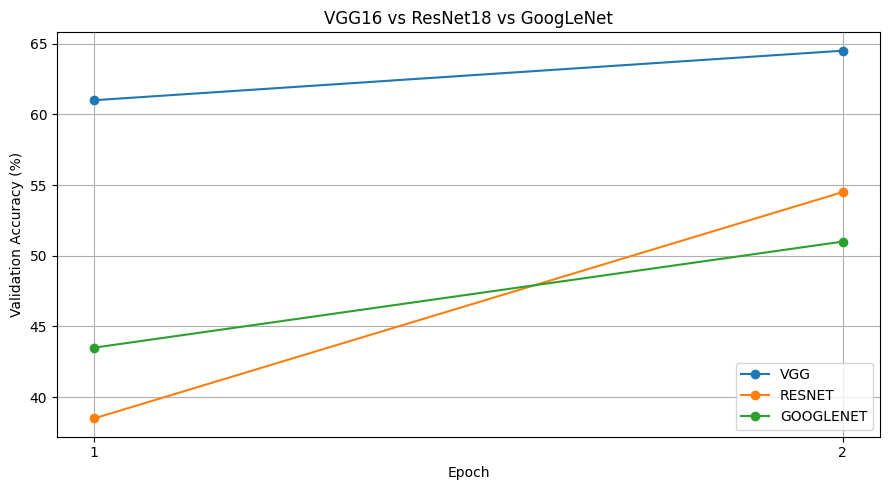


Final Model Comparison
--------------------------------------------------
VGG        | Final Accuracy: 64.50% | Training Time: 4.00 min
RESNET     | Final Accuracy: 54.50% | Training Time: 0.60 min
GOOGLENET  | Final Accuracy: 51.00% | Training Time: 0.96 min

Total time: 5.88 minutes

Custom image not found: download.jpeg
Skipping custom-image prediction.

Experiment completed successfully!


In [1]:

# ==========================================
# Exp-5: Comparative Analysis of VGG16, ResNet18, GoogLeNet
# ==========================================

# Step 1: Import Required Libraries
import os
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, Subset
from PIL import Image

# Step 2: Configure Device and Parameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 16
EPOCHS = 2
NUM_IMAGES = 1000
IMAGE_SIZE = 96
NUM_WORKERS = 0

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True
else:
    print("Using CPU. Training may take longer.")

# Step 3: Load and Preprocess CIFAR-10
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

print("\nLoading CIFAR-10 dataset...")

dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

dataset = Subset(dataset, range(NUM_IMAGES))

# Split into training and validation data
generator = torch.Generator().manual_seed(42)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = torch.utils.data.random_split(
    dataset,
    [train_size, val_size],
    generator=generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

# Step 4: Load Pretrained Models
def get_model(name):
    print(f"\nLoading pretrained {name.upper()}...")

    if name == "vgg":
        model = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT
        )

        for param in model.parameters():
            param.requires_grad = False

        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features, 10
        )

    elif name == "resnet":
        model = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        for param in model.parameters():
            param.requires_grad = False

        model.fc = nn.Linear(
            model.fc.in_features, 10
        )

    elif name == "googlenet":
        model = models.googlenet(
            weights=models.GoogLeNet_Weights.DEFAULT,
            aux_logits=True
        )

        for param in model.parameters():
            param.requires_grad = False

        model.fc = nn.Linear(
            model.fc.in_features, 10
        )

        # Enable auxiliary classifiers for training
        model.aux1.fc2 = nn.Linear(
            model.aux1.fc2.in_features, 10
        )

        model.aux2.fc2 = nn.Linear(
            model.aux2.fc2.in_features, 10
        )

    else:
        raise ValueError("Unknown model name")

    return model.to(device)

# Step 5: Train and Evaluate Each Model
def train_and_evaluate(model, name):
    trainable_params = [
        p for p in model.parameters() if p.requires_grad
    ]

    optimizer = optim.Adam(
        trainable_params,
        lr=0.001
    )

    criterion = nn.CrossEntropyLoss()
    train_history = []
    val_history = []

    start_time = time.time()

    for epoch in range(EPOCHS):
        model.train()
        correct = 0
        total = 0
        total_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)

            if hasattr(outputs, "logits"):
                # GoogLeNet training outputs
                loss = criterion(outputs.logits, labels)

                if outputs.aux_logits1 is not None:
                    loss += 0.3 * criterion(
                        outputs.aux_logits1, labels
                    )

                if outputs.aux_logits2 is not None:
                    loss += 0.3 * criterion(
                        outputs.aux_logits2, labels
                    )

                predictions = outputs.logits
            else:
                loss = criterion(outputs, labels)
                predictions = outputs

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct += (predictions.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_accuracy = 100 * correct / total
        train_history.append(train_accuracy)

        # Validation
        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                if hasattr(outputs, "logits"):
                    outputs = outputs.logits

                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

        val_accuracy = 100 * correct / total
        val_history.append(val_accuracy)

        print(
            f"{name.upper()} | Epoch {epoch + 1}/{EPOCHS} | "
            f"Loss: {total_loss / len(train_loader):.4f} | "
            f"Train Accuracy: {train_accuracy:.2f}% | "
            f"Validation Accuracy: {val_accuracy:.2f}%"
        )

    elapsed = time.time() - start_time

    print(f"{name.upper()} time: {elapsed / 60:.2f} minutes")

    return model, train_history, val_history, elapsed

# Step 6: Compare VGG16, ResNet18, and GoogLeNet
results = {}
trained_models = {}
training_times = {}

experiment_start = time.time()

for name in ["vgg", "resnet", "googlenet"]:
    print("\n" + "=" * 45)
    print("MODEL:", name.upper())
    print("=" * 45)

    model = get_model(name)

    model, train_acc, val_acc, elapsed = train_and_evaluate(
        model, name
    )

    results[name] = {
        "train": train_acc,
        "val": val_acc
    }

    trained_models[name] = model
    training_times[name] = elapsed

    torch.save(model.state_dict(), f"{name}_best.pth")

experiment_time = time.time() - experiment_start

# Step 7: Plot Validation Accuracy
plt.figure(figsize=(9, 5))

for name, result in results.items():
    plt.plot(
        range(1, EPOCHS + 1),
        result["val"],
        marker="o",
        label=name.upper()
    )

plt.title("VGG16 vs ResNet18 vs GoogLeNet")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Step 8: Display Final Results
print("\nFinal Model Comparison")
print("-" * 50)

for name, result in results.items():
    print(
        f"{name.upper():10} | "
        f"Final Accuracy: {result['val'][-1]:.2f}% | "
        f"Training Time: {training_times[name] / 60:.2f} min"
    )

print(f"\nTotal time: {experiment_time / 60:.2f} minutes")

# Step 9: Predict a Custom Image (Optional)
def predict_image(image_path):
    if not os.path.exists(image_path):
        print(f"\nCustom image not found: {image_path}")
        print("Skipping custom-image prediction.")
        return

    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    print("\nPredictions for:", image_path)

    for name, model in trained_models.items():
        model.eval()

        with torch.no_grad():
            outputs = model(image)

            if hasattr(outputs, "logits"):
                outputs = outputs.logits

            probabilities = torch.softmax(outputs, dim=1)
            confidence, predicted = probabilities.max(1)

        print(
            f"{name.upper():10} -> "
            f"{class_names[predicted.item()]:12} "
            f"Confidence: {confidence.item() * 100:.2f}%"
        )

# Put download.jpeg in the working directory to test it
predict_image("download.jpeg")

print("\nExperiment completed successfully!")